In [1]:
import pandas as pd


In [2]:
teams_data = pd.read_csv("../data/teams_post.csv")
series_data = pd.read_csv("../data/series_post.csv")
players_teams_data = pd.read_csv("../data/players_teams.csv")
awards_players_data = pd.read_csv("../data/awards_players.csv")
coaches_data = pd.read_csv("../data/coaches.csv")

Cleaning teams_post - outliers detection 

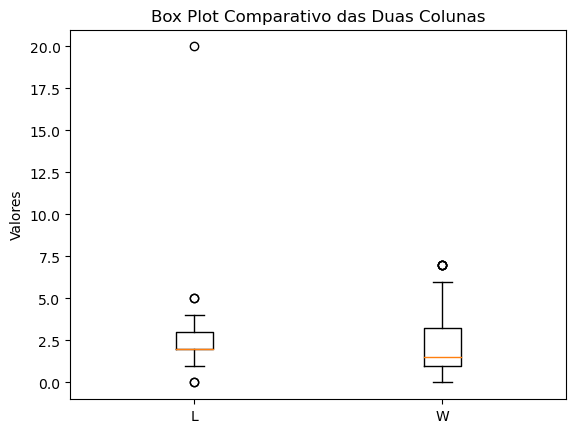

In [3]:
import matplotlib.pyplot as plt
losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()


tendo em conta que é muito improvável haver 20 derrotas, conclui-se a existência  de um outlier

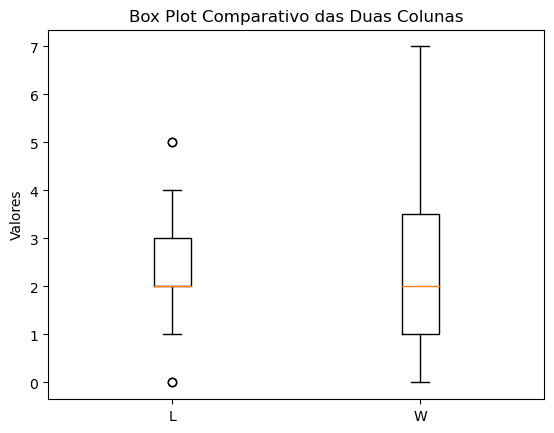

In [4]:
teams_data = teams_data.drop(17)

#filtered_data = teams_data[teams_data['year'] == 3]
#print(filtered_data['L'])

losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()


Comparison of WINS on both tables

In [5]:
# Agrupe os dados por "tmIDWinner" e "year" e calcule a soma de "W" para cada combinação
result = series_data.groupby(['tmIDWinner', 'year'])['W'].sum().reset_index()
result_sorted = result.sort_values(by='year')
print(result_sorted)



   tmIDWinner  year  W
1         CLE     1  2
23        NYL     1  4
16        LAS     1  2
11        HOU     1  6
0         CHA     2  4
30        SAC     2  2
24        NYL     2  2
17        LAS     2  6
25        NYL     3  4
38        UTA     3  2
18        LAS     3  6
39        WAS     3  2
19        LAS     4  4
31        SAC     4  2
2         CON     4  2
6         DET     4  6
37        SEA     5  6
32        SAC     5  2
26        NYL     5  2
3         CON     5  4
12        HOU     6  2
13        IND     6  2
33        SAC     6  7
4         CON     6  4
34        SAC     7  4
7         DET     7  7
20        LAS     7  2
5         CON     7  2
28        PHO     8  7
14        IND     8  2
35        SAS     8  2
8         DET     8  4
27        NYL     9  2
9         DET     9  7
36        SAS     9  4
21        LAS     9  2
10        DET    10  2
15        IND    10  4
22        LAS    10  2
29        PHO    10  7


a teams_post é a soma das vitórias+derrotas destes jogos de playoff que ocorrem anualmente, mas se repararmos alguns dados não estão coerentes em ambas as tabelas como esta linha por ex : 1,"CLE","WNBA",3,3
pois indica que houve 3 vitórias da equipa CLE no ano 1 e na verdade houve apenas duas (apesar de os restantes valores estarem corretos)

daqui conclui-se não só que a teams_post não é necessária não só por ter dados errados mas também por estar tudo (mais explícito na tabela series_post)

Cleaning series_post - outliers detection 

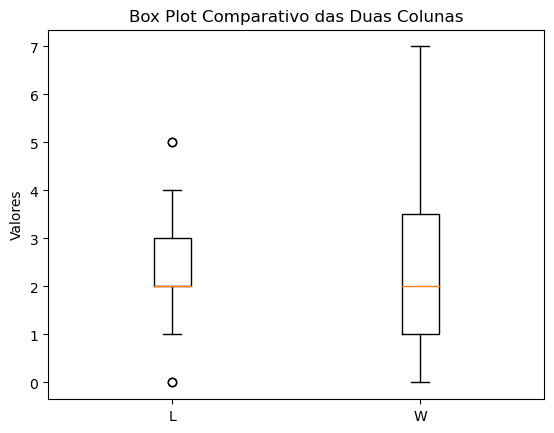

In [6]:
import matplotlib.pyplot as plt
losses = teams_data['L']
wins = teams_data['W']

plt.boxplot([losses, wins])
plt.title('Box Plot Comparativo das Duas Colunas')
plt.xticks([1, 2], ['L', 'W'])
plt.ylabel('Valores')
plt.show()

Analysis of wins + losses on each year on playoffs

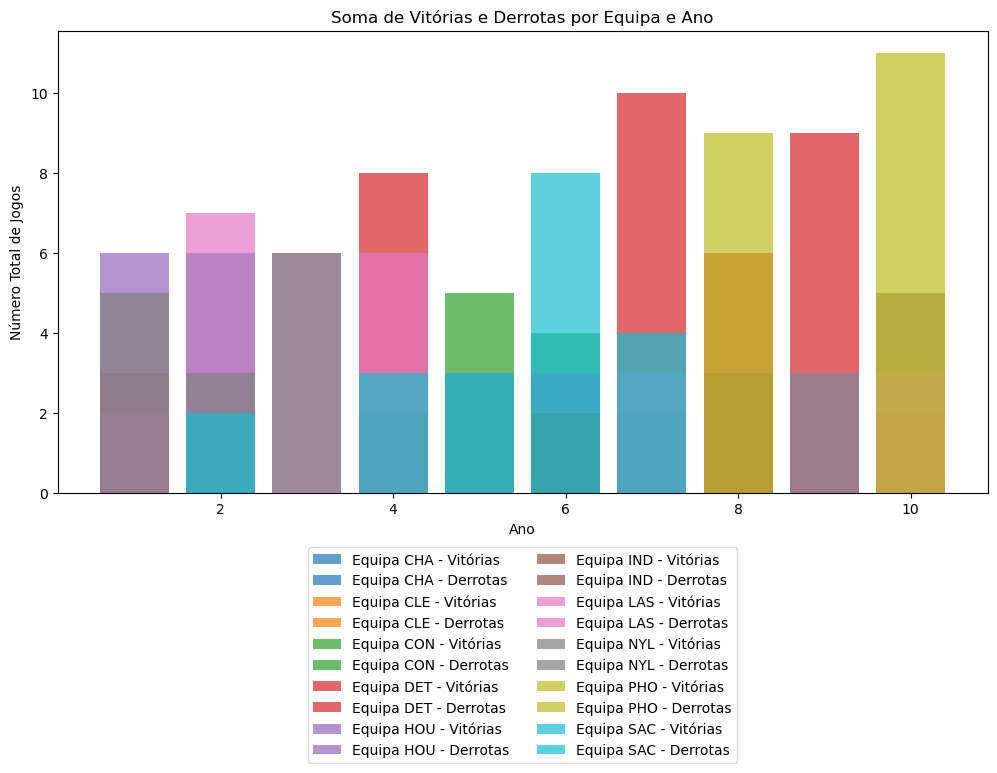

In [7]:
import seaborn as sns

# DataFrame com as informações de vitórias e derrotas de cada equipa em cada ano
r = series_data.groupby(['tmIDWinner', 'year'])[['W', 'L']].sum().reset_index()

# dicionário que mapeia cada equipa a uma cor única
team_colors = {team: color for team, color in zip(r['tmIDWinner'].unique(), sns.color_palette())}

# gráfico de barras 
plt.figure(figsize=(12, 6))

for team in r['tmIDWinner'].unique():
    if team in team_colors:
        team_data = r[r['tmIDWinner'] == team]
        plt.bar(
            team_data['year'], team_data['W'], label=f'Equipa {team} - Vitórias',
            color=team_colors[team], alpha=0.7
        )
        plt.bar(
            team_data['year'], team_data['L'], label=f'Equipa {team} - Derrotas',
            color=team_colors[team], alpha=0.7, bottom=team_data['W']
        )

plt.xlabel('Ano')
plt.ylabel('Número Total de Jogos')
plt.title('Soma de Vitórias e Derrotas por Equipa e Ano')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.6), ncol=2)
plt.show()


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

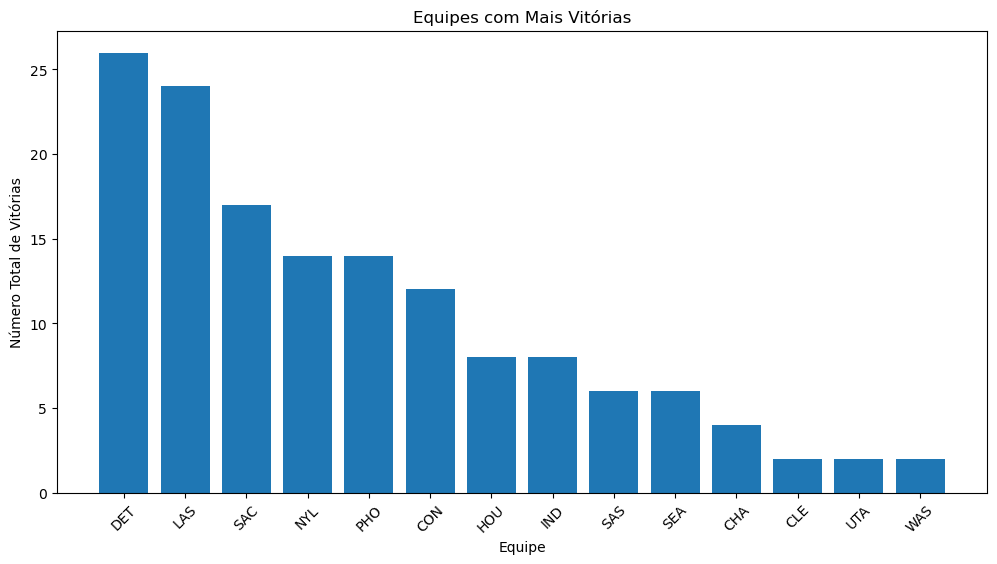

In [ ]:
team_wins = series_data.groupby('tmIDWinner')['W'].sum().reset_index()

# Número de vitórias em ordem decrescente
team_wins = team_wins.sort_values(by='W', ascending=False)

# Gráfico de barras com as equipas 
plt.figure(figsize=(12, 6))
plt.bar(team_wins['tmIDWinner'], team_wins['W'])
plt.xlabel('Equipe')
plt.ylabel('Número Total de Vitórias')
plt.title('Equipas com Mais Vitórias')
plt.xticks(rotation=45)

   tmIDWinner  year  W
11        HOU     1  6
17        LAS     2  6
18        LAS     3  6
6         DET     4  6
37        SEA     5  6
33        SAC     6  7
7         DET     7  7
28        PHO     8  7
9         DET     9  7
29        PHO    10  7


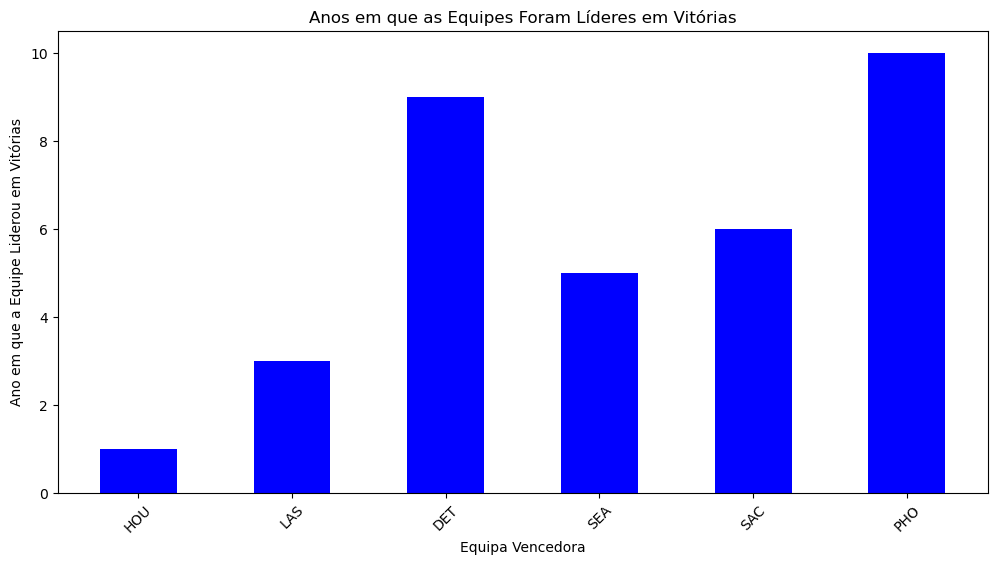

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Agrupar os dados por equipa e ano e somar as vitórias para cada equipa em cada ano
team_wins = series_data.groupby(['tmIDWinner', 'year'])['W'].sum().reset_index()

# Encontrar a equipa com mais vitórias em cada ano
top_teams = team_wins.loc[team_wins.groupby('year')['W'].idxmax()]
print(top_teams)

# Criar um gráfico de barras com os anos em que as equipas foram líderes em vitórias
plt.figure(figsize=(12, 6))
plt.bar(top_teams['tmIDWinner'], top_teams['year'], color='blue', width=0.5)  # Largura personalizada das barras
plt.xlabel('Equipa Vencedora')
plt.ylabel('Ano em que a Equipe Liderou em Vitórias')
plt.title('Anos em que as Equipes Foram Líderes em Vitórias')
plt.xticks(rotation=45)  # Rotação dos nomes das equipas para melhor legibilidade

plt.show()


Association between coaches and players of the winnning teams with the respective awards

ver como se chamam os jogadores das equipas vencedoras em cada ano

In [ ]:
# Renomear as colunas 'tmIDWinner' e 'year' em 'top_teams' para coincidir com as colunas em 'teams_player'
top_teams.rename(columns={'tmIDWinner': 'tmID', 'year': 'year'}, inplace=True)
one_col = pd.merge(top_teams, players_teams_data , on=['tmID', 'year'], how='inner')

# Selecione as colunas 'playerID' e 'year' da tabela result
one_col = one_col[['playerID', 'year']]

# Imprima o resultado
print(one_col)

       playerID  year
0    arcaija01w     1
1    coopecy01w     1
2    gibsoke01w     1
3    jacksta01w     1
4    johnsti01w     1
..          ...   ...
125  smithta01w    10
126  swanike01w    10
127  tauradi01w    10
128  taylope01w    10
129  willile01w    10

[130 rows x 2 columns]


ver em que anos alguns destes jogadores ganharam prémios

In [ ]:
# Junção das tabelas 'one_col' (que contém 'playerID' e 'year') com 'awards_players_data'
awards_players = pd.merge(one_col, awards_players_data, on=['playerID', 'year'], how='inner')

# Verificar se há alguma correspondência
if not awards_players.empty:
    print("Jogadores nas equipas vencedoras que também receberam prémios:")
    print(awards_players)



Jogadores nas equipas vencedoras que também receberam prémios:
      playerID  year                               award  lgID
0   coopecy01w     1    WNBA Finals Most Valuable Player  WNBA
1   swoopsh01w     1        Defensive Player of the Year  WNBA
2   swoopsh01w     1                Most Valuable Player  WNBA
3   thompti01w     1  All-Star Game Most Valuable Player  WNBA
4   leslili01w     2  All-Star Game Most Valuable Player  WNBA
5   leslili01w     2                Most Valuable Player  WNBA
6   leslili01w     2    WNBA Finals Most Valuable Player  WNBA
7   leslili01w     3  All-Star Game Most Valuable Player  WNBA
8   leslili01w     3    WNBA Finals Most Valuable Player  WNBA
9    fordch01w     4                  Rookie of the Year  WNBA
10  rileyru01w     4    WNBA Finals Most Valuable Player  WNBA
11  lennobe01w     5    WNBA Finals Most Valuable Player  WNBA
12  griffyo01w     6    WNBA Finals Most Valuable Player  WNBA
13  nolande01w     7    WNBA Finals Most Valuable Playe

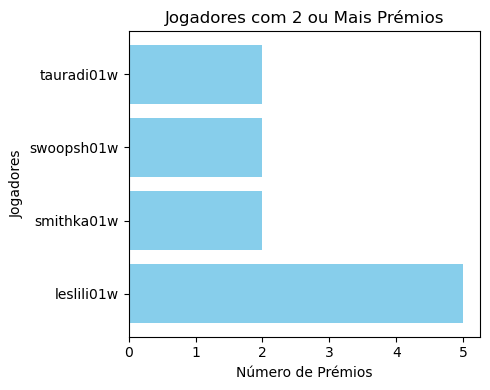

In [ ]:
import matplotlib.pyplot as plt

# Vamos remover a coluna 'lgID'.
awards_players = awards_players.drop('lgID', axis=1)

# incluir apenas jogadores com 2 ou mais prêmios
awards_players_filtered = awards_players[awards_players.groupby('playerID')['award'].transform('count') >= 2]

# contagem de prémios para cada jogador
player_award_counts = awards_players_filtered.groupby('playerID')['award'].count().reset_index()

# Ordenar os dados pela contagem de prémios em ordem decrescente
player_award_counts = player_award_counts.sort_values(by='award', ascending=False)

players = player_award_counts['playerID']
awards = player_award_counts['award']

# gráfico de barras 
plt.figure(figsize=(5, 4))
plt.barh(players, awards, color='skyblue')
plt.xlabel('Número de Prémios')
plt.ylabel('Jogadores')
plt.title('Jogadores com 2 ou Mais Prémios')
plt.tight_layout()
plt.show()


fazer o mesmo processo - ver os coaches

In [ ]:
# junção das tabelas com base nas colunas 'tmID' em ambas as tabelas
merged_data = top_teams.merge(coaches_data, how='left')

unique_coaches = merged_data.drop_duplicates(subset=['tmID', 'coachID'])

# Para exibir a lista de treinadores únicos com suas respectivas equipes
print(unique_coaches[['tmID', 'coachID']])


  tmID     coachID
0  HOU  chancva99w
1  LAS  coopemi01w
3  DET  laimbbi01w
4  SEA  donovan99w
5  SAC  whisejo99w
7  PHO  westhpa99w
9  PHO  gaineco01w


Coaches que ganharam prémios

In [ ]:
# Primeiro, realize a junção entre 'unique_coaches' e 'awards_players' com base na coluna 'coach_player_id'.

merged_data2 = unique_coaches.merge(awards_players_data, left_on='coachID', right_on='playerID', how='inner')
# Agora, 'merged_data' conterá informações de treinadores premiados e os jogadores correspondentes.

# Para verificar quais jogadores (playerID) estão associados a treinadores premiados.
coach_award_winners = merged_data2['coachID']

# Exiba a lista de jogadores associados a treinadores premiados.
print(coach_award_winners)


0    coopemi01w
1    laimbbi01w
2    whisejo99w
Name: coachID, dtype: object
